<a href="https://colab.research.google.com/github/Panlyzar/project_suui2/blob/main/SUI_CV3__Rozhodovac%C3%AD_stromy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CVIČENÍ 3. -  Rozhodovací stromy
---
Toto cvičení bude zaměřeno na základy zajímavé problematiky z oblasti ML a to je **klasifikace**. Klasifikace je obvykle **strojové učení s učitelem**, to znamená že algoritmus se učí na základě *tréninkových dat*, která obsahují příklady s přiřazenými cílovými třídami nebo kategoriemi. Cílem je naučit model rozpoznávat vzory v datech a přiřazovat novým, neznámým příkladům **správnou třídu** na základě těchto vzorů. Ve stejné kategorii, tedy učení s učitelem se nachází i *lineární regrese* z posledního cvičení. 💡
> Klasifikační třída může být třeba `"kolečko"` a `"čtvreček"`, nebo `"pes"` a `"kočka"`, či jen `"1"` a `"0"`. Když jsou tyto třídy pouze 2, tedy například `"1"` a `"0"`, tak mluvíme o *binární klasifikaci*, když je jich více tak se jedná o *multi-class* klasifikaci.  Jinak řešeno, **model se má naučit že kolečka jsou kolečka a čtverečky čtverečky**. ⭕ ⏹





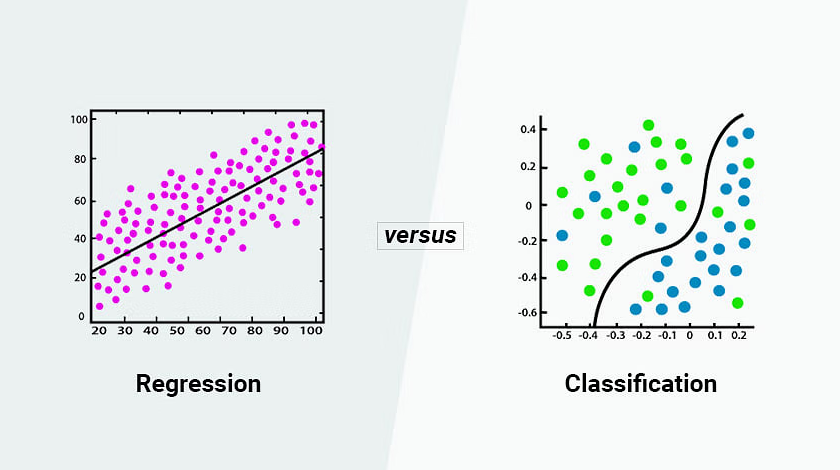

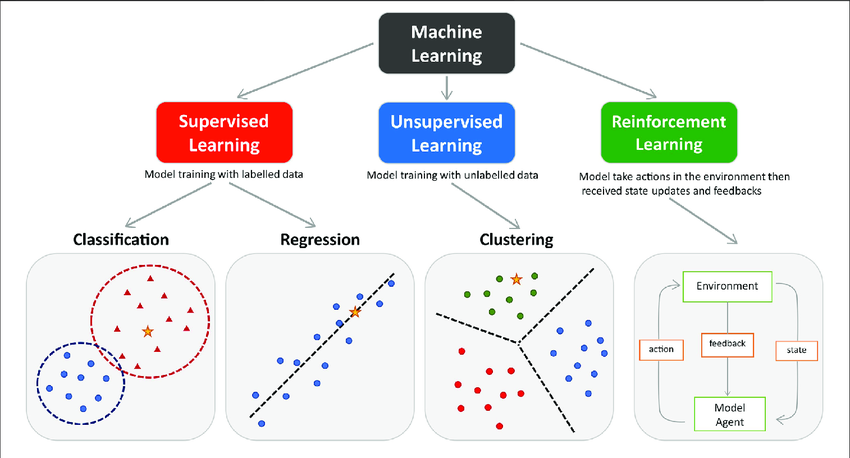

## Rozhodovací stromy - Decision Trees
Jedná se o jednu z efektivních metod **klasifikace**, využívá binární větvení (Binary Tree) které se větví na základě jedné či více vlatností, tímto postupným větvením se dostává až na "listy" stromu které symbolizují klasifikační třídy.

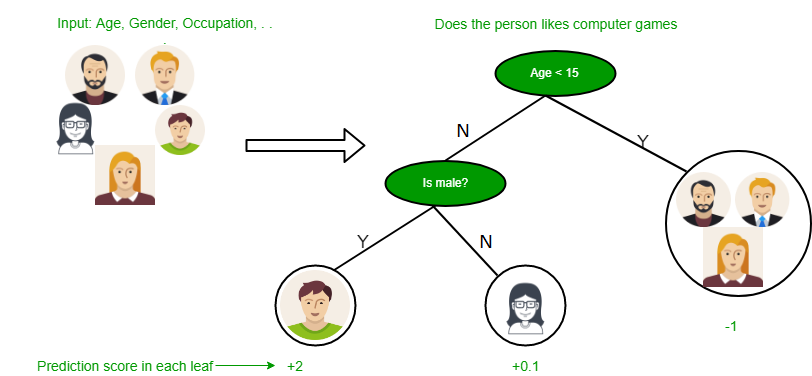

In [ ]:
# Import základních ML knihoven - best practices
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Knihovna pro práci s Decicision Trees
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.tree import plot_tree

## ČÁST 1: Příprava dat: Iris
---
Opět a znovu bude potřeba načíst data a převést je na validní `dataset`.
Použijeme *Iris* dataset který se hodí na tento typ klasifikační úlohy [(zdroj: www.lac.inpe.br)](http://www.lac.inpe.br/~rafael.santos/Docs/CAP394/WholeStory-Iris.html).

### Popis datasetu:
*Dataset Iris obsahuje čtyři rysy (délku a šířku kališních a korunních lístků) u 50 vzorků tří druhů kosatců (Iris setosa, Iris virginica a Iris versicolor). Tyto měření byla použita k vytvoření lineárního diskriminačního modelu pro klasifikaci těchto druhů. Dataset je často používán v datovém dolování, příkladech klasifikace a shlukování a k testování algoritmů.*

**Sloupce:**
- sepal.length: délka kališních lístků
- sepal.width: šířka kališních lístků
- petal.length: délka korunních lístků
- petal.width: šířka korunních lístků
- variety: druh rostliny

**Cíl:**
Hlavním cílem tohoto datasetu je rozpoznávat druh rostliny na základě délky a šířky kalačních a korunních lístků.

In [ ]:
from sklearn.datasets import load_iris
# Načtení datasetu Iris
iris = load_iris()
iris

{'data': array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2],
        [5.4, 3.9, 1.7, 0.4],
        [4.6, 3.4, 1.4, 0.3],
        [5. , 3.4, 1.5, 0.2],
        [4.4, 2.9, 1.4, 0.2],
        [4.9, 3.1, 1.5, 0.1],
        [5.4, 3.7, 1.5, 0.2],
        [4.8, 3.4, 1.6, 0.2],
        [4.8, 3. , 1.4, 0.1],
        [4.3, 3. , 1.1, 0.1],
        [5.8, 4. , 1.2, 0.2],
        [5.7, 4.4, 1.5, 0.4],
        [5.4, 3.9, 1.3, 0.4],
        [5.1, 3.5, 1.4, 0.3],
        [5.7, 3.8, 1.7, 0.3],
        [5.1, 3.8, 1.5, 0.3],
        [5.4, 3.4, 1.7, 0.2],
        [5.1, 3.7, 1.5, 0.4],
        [4.6, 3.6, 1. , 0.2],
        [5.1, 3.3, 1.7, 0.5],
        [4.8, 3.4, 1.9, 0.2],
        [5. , 3. , 1.6, 0.2],
        [5. , 3.4, 1.6, 0.4],
        [5.2, 3.5, 1.5, 0.2],
        [5.2, 3.4, 1.4, 0.2],
        [4.7, 3.2, 1.6, 0.2],
        [4.8, 3.1, 1.6, 0.2],
        [5.4, 3.4, 1.5, 0.4],
        [5.2, 4.1, 1.5, 0.1],
  

### Explorační analýza
Opět provedeme rychlou **EDA** (*Exploration Data Analysis*). Krom známých předchozích metodik přidáme vykreslení tzv. *heatmapy*.  

In [ ]:
# Převod na DataFrame
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["variety"] = iris.target
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),variety
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [ ]:
# Základní statistika
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),variety
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [ ]:
# Kontrola chybějících hodnot (null, NA)
df.isnull().sum()

,0
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
variety,0


In [ ]:
# Odstraň záznamy s chybějící hodnotou
df.dropna(inplace=True)

In [ ]:
# Datové typy sloupců
df.dtypes

,0
sepal length (cm),float64
sepal width (cm),float64
petal length (cm),float64
petal width (cm),float64
variety,int64


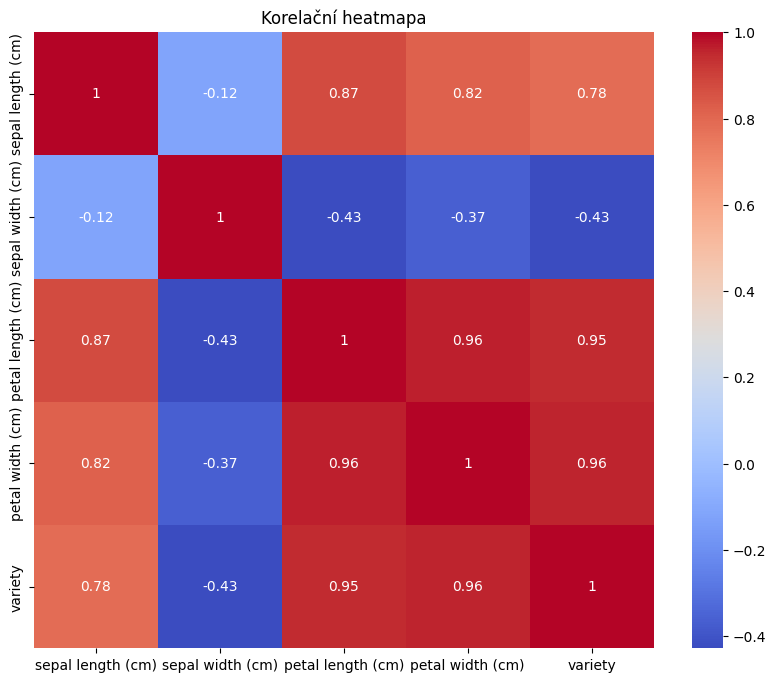

In [ ]:
# Korelační heatmapa - ukazuje nám závislost mezi jednotlivými vlastnostmi
"""
Warning:
Pro generování heatmapy je nutné použít knihovnu seaborn (sns),
která slouží k vykreslování pokročilých grafů a je kompatibilní s knihovnou matplotlib (plt).
"""
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Korelační heatmapa')
plt.show()

✍ *Vsuvka:* Zde vidíme že heatmapa je "teplá" 🔥 a proto můžeme říct že mezi jednotlivými vlastnosti je na první pohled korelace - **jsou na sobě závislé**. Tedy, lze třeba říct že když je okvětní lístek dlouhý, bude zároveň úzký, a podobně. To by nám mohlo pomoci říct **které vlastnosti jsou důležitější než ostatní** a které budou pro trénování rozhodující. Jsou to pak důležitá dělící kritéria.  Pozor, stejně důležitá je i záporná korelace - "studená" 🧊!

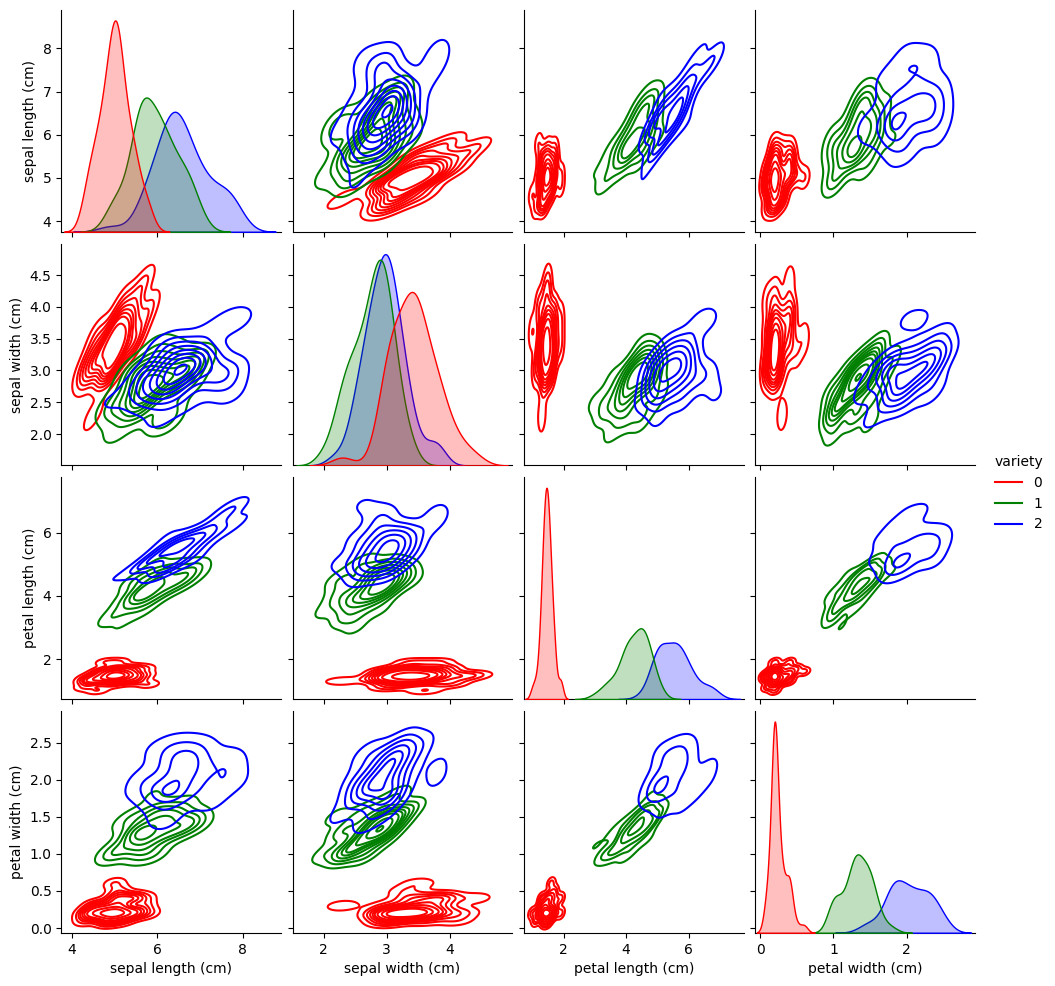

In [ ]:
# SNS umí generovat elegantní sadu tzv. pair-plot grafů (kombinuje do kříže všechny vlastnosti)
"""
Rozlišení dat na základě atributu "variety" - druhu rostliny, nám pomáhá si držet lepší přehled o vzájemém překrývání vlastností dat.
Pomocí atributu pallete lze namapovat numerickou hodnotu druhu na barvu.
"""
sns.pairplot(df, kind="kde", hue="variety", palette={0:"r",1:"g",2:"b"})

## Rozdělení dat
Opět je třeba rozdělit data na vstupy a výstupy - `X` a `y`. S tím nám pomůže funkce `train_test_split` která nám předrozdělí čistá data na trénovací a testovací množiny. 🎯 Jako vstupy `X` použijeme naměřené vlastnosti rostliny (neboli `data`) a jako výstupy `y` potřebujeme konktrétní třídu - tedy druh rostliny. Tomu odpovídá sloupec `variety` neboli `target`.

In [ ]:
# Rozdělení na X a y - vstupy a výstupy
"""
Warning:
Protože používáme preloaded Iris dataset, je rozdělení jednotuché - data a target
"""
X = iris.data
y = iris.target

# Dělení dat na trénovací a testovací, v poměru 80/20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((120, 4), (30, 4), (120,), (30,))

In [ ]:
# Náhled dat
X_train[:5]

array([[4.6, 3.6, 1. , 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [6.7, 3.1, 4.4, 1.4],
       [4.8, 3.4, 1.6, 0.2],
       [4.4, 3.2, 1.3, 0.2]])

In [ ]:
y_train[:5]

array([0, 0, 1, 0, 0])

### Vytvoření modelu
Dataset je připraven, nyní nám stačí vytvořit, natrénovat a otestovat model.  

In [ ]:
# Vytvoření instance rozhodovacího stromu
clf = DecisionTreeClassifier(criterion="gini", splitter="best",random_state=42)

In [ ]:
# Trénování modelu - funce fit
clf.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

✍ *Vsuvka:* Random state nastaví počáteční parametry modelu náhodně, to pomáhá při trénování a zajistí pokaždé jiný trénovací průběh.  

In [ ]:
# Otestování skore funkce - výsledek mezi 0 a 1, čím blíže k 1, tím lépe je model schopen klasifikovat data a vedl si lépe
clf.score(X_test, y_test)

1.0

In [ ]:
X_fict = [[4.6, 3.6, 1. , 0.2]]
clf.predict(X_fict)

array([0])

## Vizualizace stromu
Pro co nejlepší pochopení jak takový decision tree vlastně funguje a co dělá, je nejlepší si ho prostě vizualizovat. Na obrázku níže vidíte podle jakých podmínek a vlastností se strom větvil a postupně osekával a klasifikoval dataset. 🌳

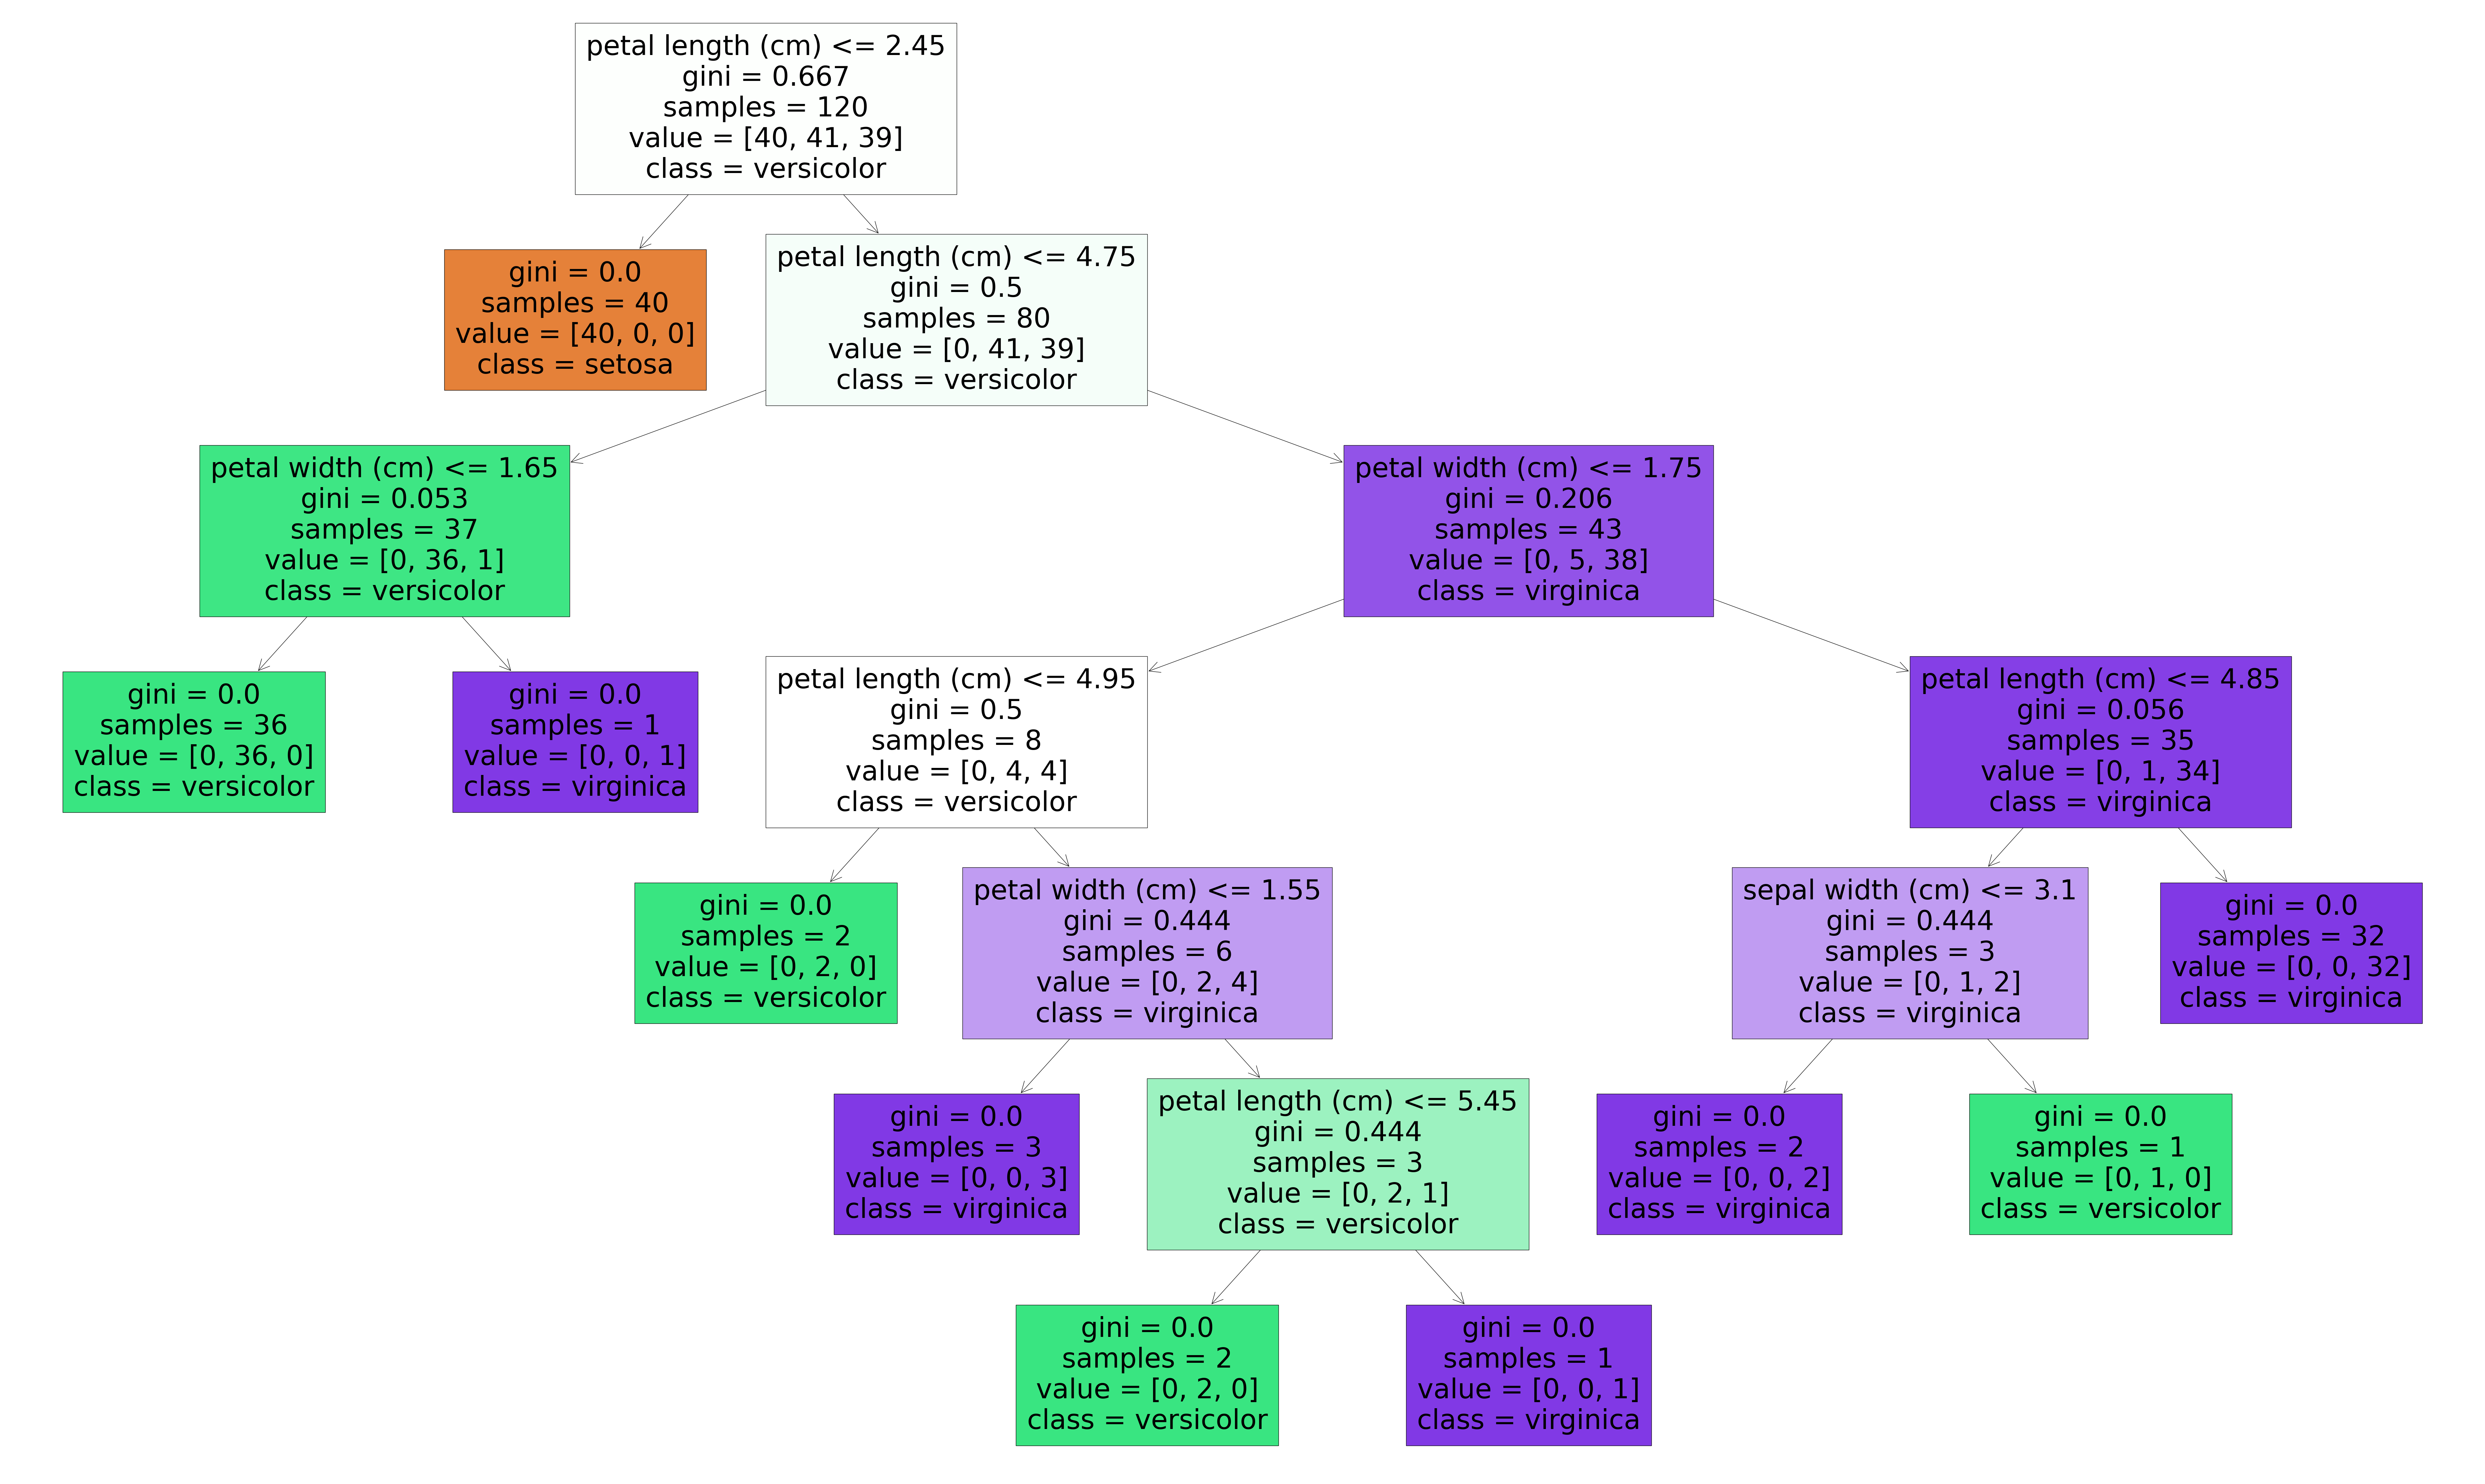

In [ ]:
# Vizualizace stromu
plt.figure(figsize=(100, 60))  # Volitelné: Nastavení velikosti obrázku
# Používáme funkci plot tree kompatipilní s Matplotlib
plot_tree(clf, filled=True, feature_names=iris.feature_names, class_names=iris.target_names)
plt.show()

### Gini Index
Mnozí z vás si jistě všimli atributu `gini` ve vizualizaci rozhodovacího stromu - jedná se o takzvané **rozhodovací/rozdělovací kritérium** (split criterium). V zásadě se jedná o hodnotu která udává míru toho, jak dobře je daná oblast dat dělitelná - kolik obsahuje tříd a v jakém množství - distribuci.

**Definice:**

> Gini index je míra nepořádku nebo nečistoty v množině dat. Používá se zejména v kontextu klasifikačních algoritmů, jako jsou rozhodovací stromy. Při vytváření rozhodovacího stromu je cílem najít optimální rozdělení dat na jednotlivé větve tak, aby byly homogenní, tj. aby v každé větvi byla ideálně data stejného třídního označení (například samé čtverečky či kruhy). Gini index je jedním z kritérií, která se používají k určení toho, jak je dané rozdělení dat.


###ÚKOL 1:
Použijte `DecisionTree` nebo `RandomForest` klasifikátor, a zkuste natrénovat a klasifikovat tento dataset: [Palmer penguin dataset](https://www.kaggle.com/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data)
> Link na CSV. soubor: [online CSV file](https://gist.githubusercontent.com/slopp/ce3b90b9168f2f921784de84fa445651/raw/4ecf3041f0ed4913e7c230758733948bc561f434/penguins.csv)

Klasifikační vlastnost bude sloupec `sex` = to bude `y`. Jako x budou složit všechna ostatní data krom sloupců `rowid` a `year`, `species`,	`island`. Nezapomeňte odstranit nevalidní hodnoty - null a NA!

**Postup:**
- EDA
- rozdělení dat train/test
- vytvoření a trénování modelu
- test modelu
- vizualizace modelu

GL&HF! 🕶


In [ ]:
# řešení úkolu č. 2:
penguin_df = pd.read_csv("https://gist.githubusercontent.com/slopp/ce3b90b9168f2f921784de84fa445651/raw/4ecf3041f0ed4913e7c230758733948bc561f434/penguins.csv")
???

In [ ]:
# Zjisti jestli nejsou v datech NA hodnoty
???

In [ ]:
# Dropni NA hodnoty

In [ ]:
# Plotni pairplot pro sex, male modře, female červeně
???

In [ ]:
# Numerizuj sloupec "sex" na číselnou hodnotu
penguin_df["sex_class"] = ???

In [ ]:
# Rozděl vhodně vstup a výstup data
# Vstup: definuj dle pairplotu
# Výstup: pohlaví (sex)
# Nazapomen na to_numpy()
X = ???
y = ???

X.shape, y.shape

In [ ]:
# Náhled vstupu a výstupu
X[:5]

In [ ]:
y[:5]

In [ ]:
# Rozděl data na train/test pomocí train_test_split, v poměru 75/25
???

In [ ]:
# Navrhni svůj rozhodovaCÍ STROM - DecisionTreeClassifier
# Zkus nastavit kritérium i splitter
clf_penguin = ???
clf_penguin

In [ ]:
# Fitni model
???

In [ ]:
# Otestuj rychle model, pomocí score
???

In [ ]:
# Vizualizace stromu
plt.figure(figsize=(100, 60))  # Volitelné: Nastavení velikosti obrázku
# Používáme funkci plot tree kompatipilní s Matplotlib
# Dopln vhodně feature a class names
plot_tree(clf_penguin, filled=True, feature_names=???, class_names=???)
plt.show()

###ÚKOL 2:
Zkuste natrénovat místo klasifikačního stromu les - Forest. Použijte **Random Forest klasifikátor** a porovnejte výsledky s rozhodovacím stromem. (stačí `score`)  

In [ ]:
# řešení úkolu č. 1:
from sklearn.ensemble import RandomForestClassifier